In [ ]:
from multi_func import *
import torch
from torch import nn, optim
from torchvision import datasets, transforms
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from torch.utils.data import random_split
import os
os.makedirs('results', exist_ok=True)
D='cuda' if torch.cuda.is_available() else 'cpu'
print(D)

cpu


In [ ]:
%pip install scipy

In [5]:
bs = 64
LR = 1e-3
epoch = 10
cri = nn.CrossEntropyLoss()
nmt = True
mty = "CNN"
dset = "SVHN"
smp = f"results/{mty}_{dset}.pt"

In [ ]:
trans = transforms.Compose([transforms.ToTensor()])
trdsa = datasets.SVHN(root="data", split="train", download=True, transform=trans)
teds = datasets.SVHN(root="data", split="test", download=True, transform=trans)
teds.classes = [str(i) for i in range(10)]
n = int(len(trdsa) * 0.8)
trds, vads = random_split(trdsa, [n, len(trdsa) - n])
trdl = DataLoader(trds, batch_size=bs, shuffle=True)
vadl = DataLoader(vads, batch_size=bs, shuffle=False)
tedl = DataLoader(teds, batch_size=bs, shuffle=False)

In [17]:
xb, yb = next(iter(trdl))
print("이미지:", xb.shape)
print("정답:", yb.shape)

이미지: torch.Size([64, 3, 32, 32])
정답: torch.Size([64])


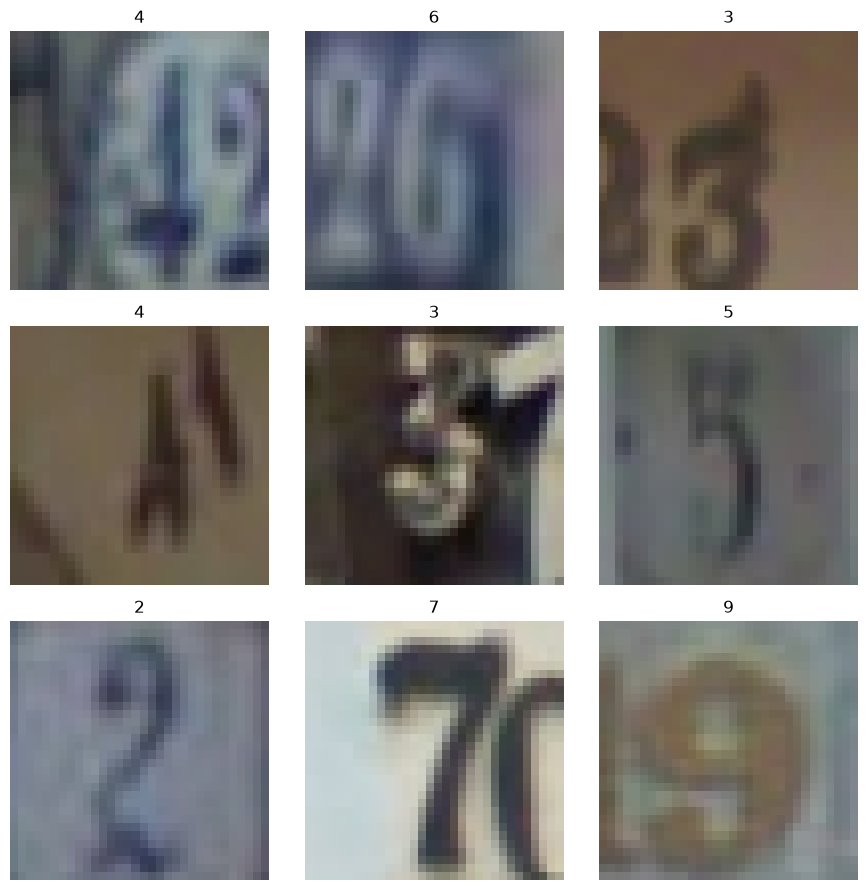

In [19]:
plt.figure(figsize=(9, 9))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(xb[i].permute(1, 2, 0))
    plt.title(classes[yb[i].item()])
    plt.axis("off")
plt.tight_layout()
plt.show()

In [23]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.c1 = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU()
        )
        self.mp = nn.MaxPool2d(2)
        self.c2 = nn.Sequential(
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU()
        )
        self.c3 = nn.Sequential(
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU()
        )
        self.avg = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(128, 10)

    def forward(self, x):
        x = self.c1(x)
        x = self.mp(x)
        x = self.c2(x)
        x = self.mp(x)
        x = self.c3(x)
        x = self.mp(x)
        x = self.avg(x)
        x = torch.flatten(x, start_dim=1)
        x = self.fc(x)
        return x

In [24]:
m = CNN().to(DEVICE)
print(m)
x = torch.randn(5, 3, 32, 32).to(DEVICE)
print(m(x).shape)

CNN(
  (c1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
  )
  (mp): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (c2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
  )
  (c3): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
  )
  (avg): AdaptiveAvgPool2d(output_size=(1, 1))
  (fc): Linear(in_features=128, out_features=10, bias=True)
)
torch.Size([5, 10])


In [25]:
m = globals()[mty]().to(D)
xb, _ = next(iter(trdl))
m.eval()
with torch.no_grad():
    print(m(xb.to(D)).shape)

torch.Size([64, 10])


epoch: 1, train loss: 1.570
epoch: 2, train loss: 0.821
epoch: 3, train loss: 0.578
epoch: 4, train loss: 0.474
epoch: 5, train loss: 0.413
epoch: 6, train loss: 0.374
epoch: 7, train loss: 0.345
epoch: 8, train loss: 0.316
epoch: 9, train loss: 0.295
epoch: 10, train loss: 0.280


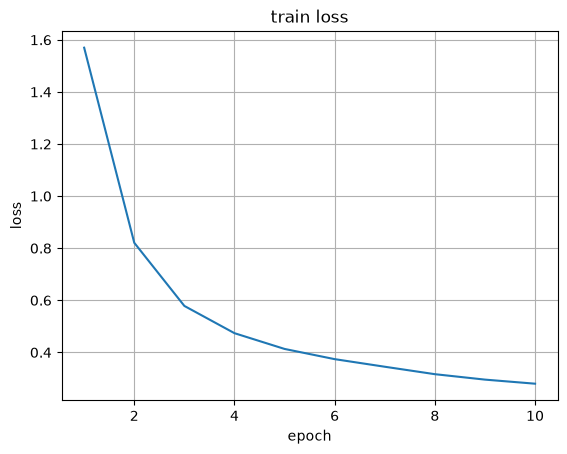

In [26]:
if nmt:
    op = optim.Adam(m.parameters(), lr=LR)
    lh = Train(m, trdl, cri, op, epoch)
    torch.save(m,smp)
    plt.figure()
    plt.plot(range(1, epoch + 1), lh)
    plt.xlabel("epoch")
    plt.ylabel("loss")
    plt.title("train loss")
    plt.grid()

test accuracy: 23095/26032 88.7%


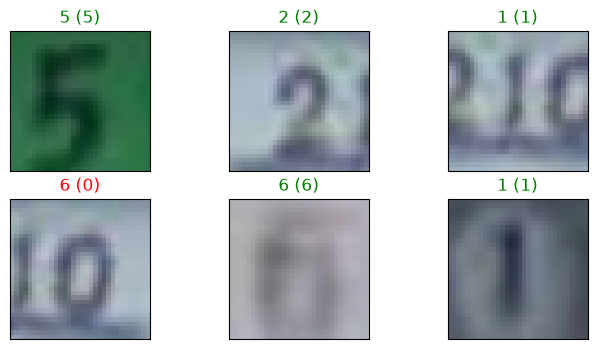

In [30]:
lm=torch.load(smp,map_location=D,weights_only=False)
Test(lm,tedl)
Test_plot(lm,tedl)

(array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]),
 [Text(0, 0, '0'),
  Text(1, 0, '1'),
  Text(2, 0, '2'),
  Text(3, 0, '3'),
  Text(4, 0, '4'),
  Text(5, 0, '5'),
  Text(6, 0, '6'),
  Text(7, 0, '7'),
  Text(8, 0, '8'),
  Text(9, 0, '9')])

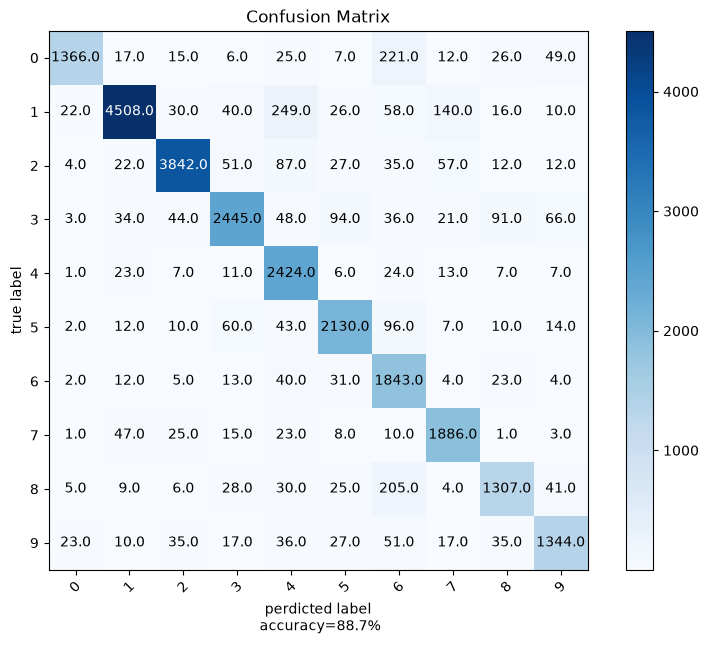

In [31]:
conf = get_conf(lm, tedl)
plot_conf_mat(conf, teds.classes)
plt.xticks(rotation=45)

torch.Size([64, 32, 32, 32])
torch.Size([64, 64, 16, 16])
torch.Size([64, 128, 8, 8])


Text(0.5, 1.0, '5 (5)')

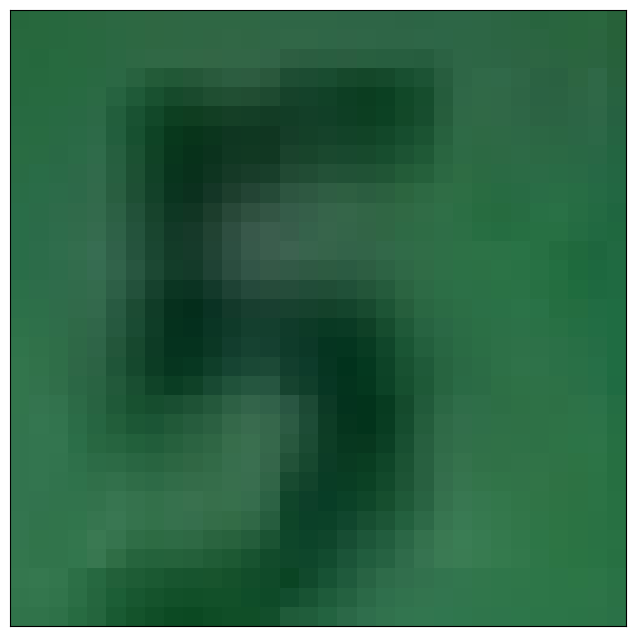

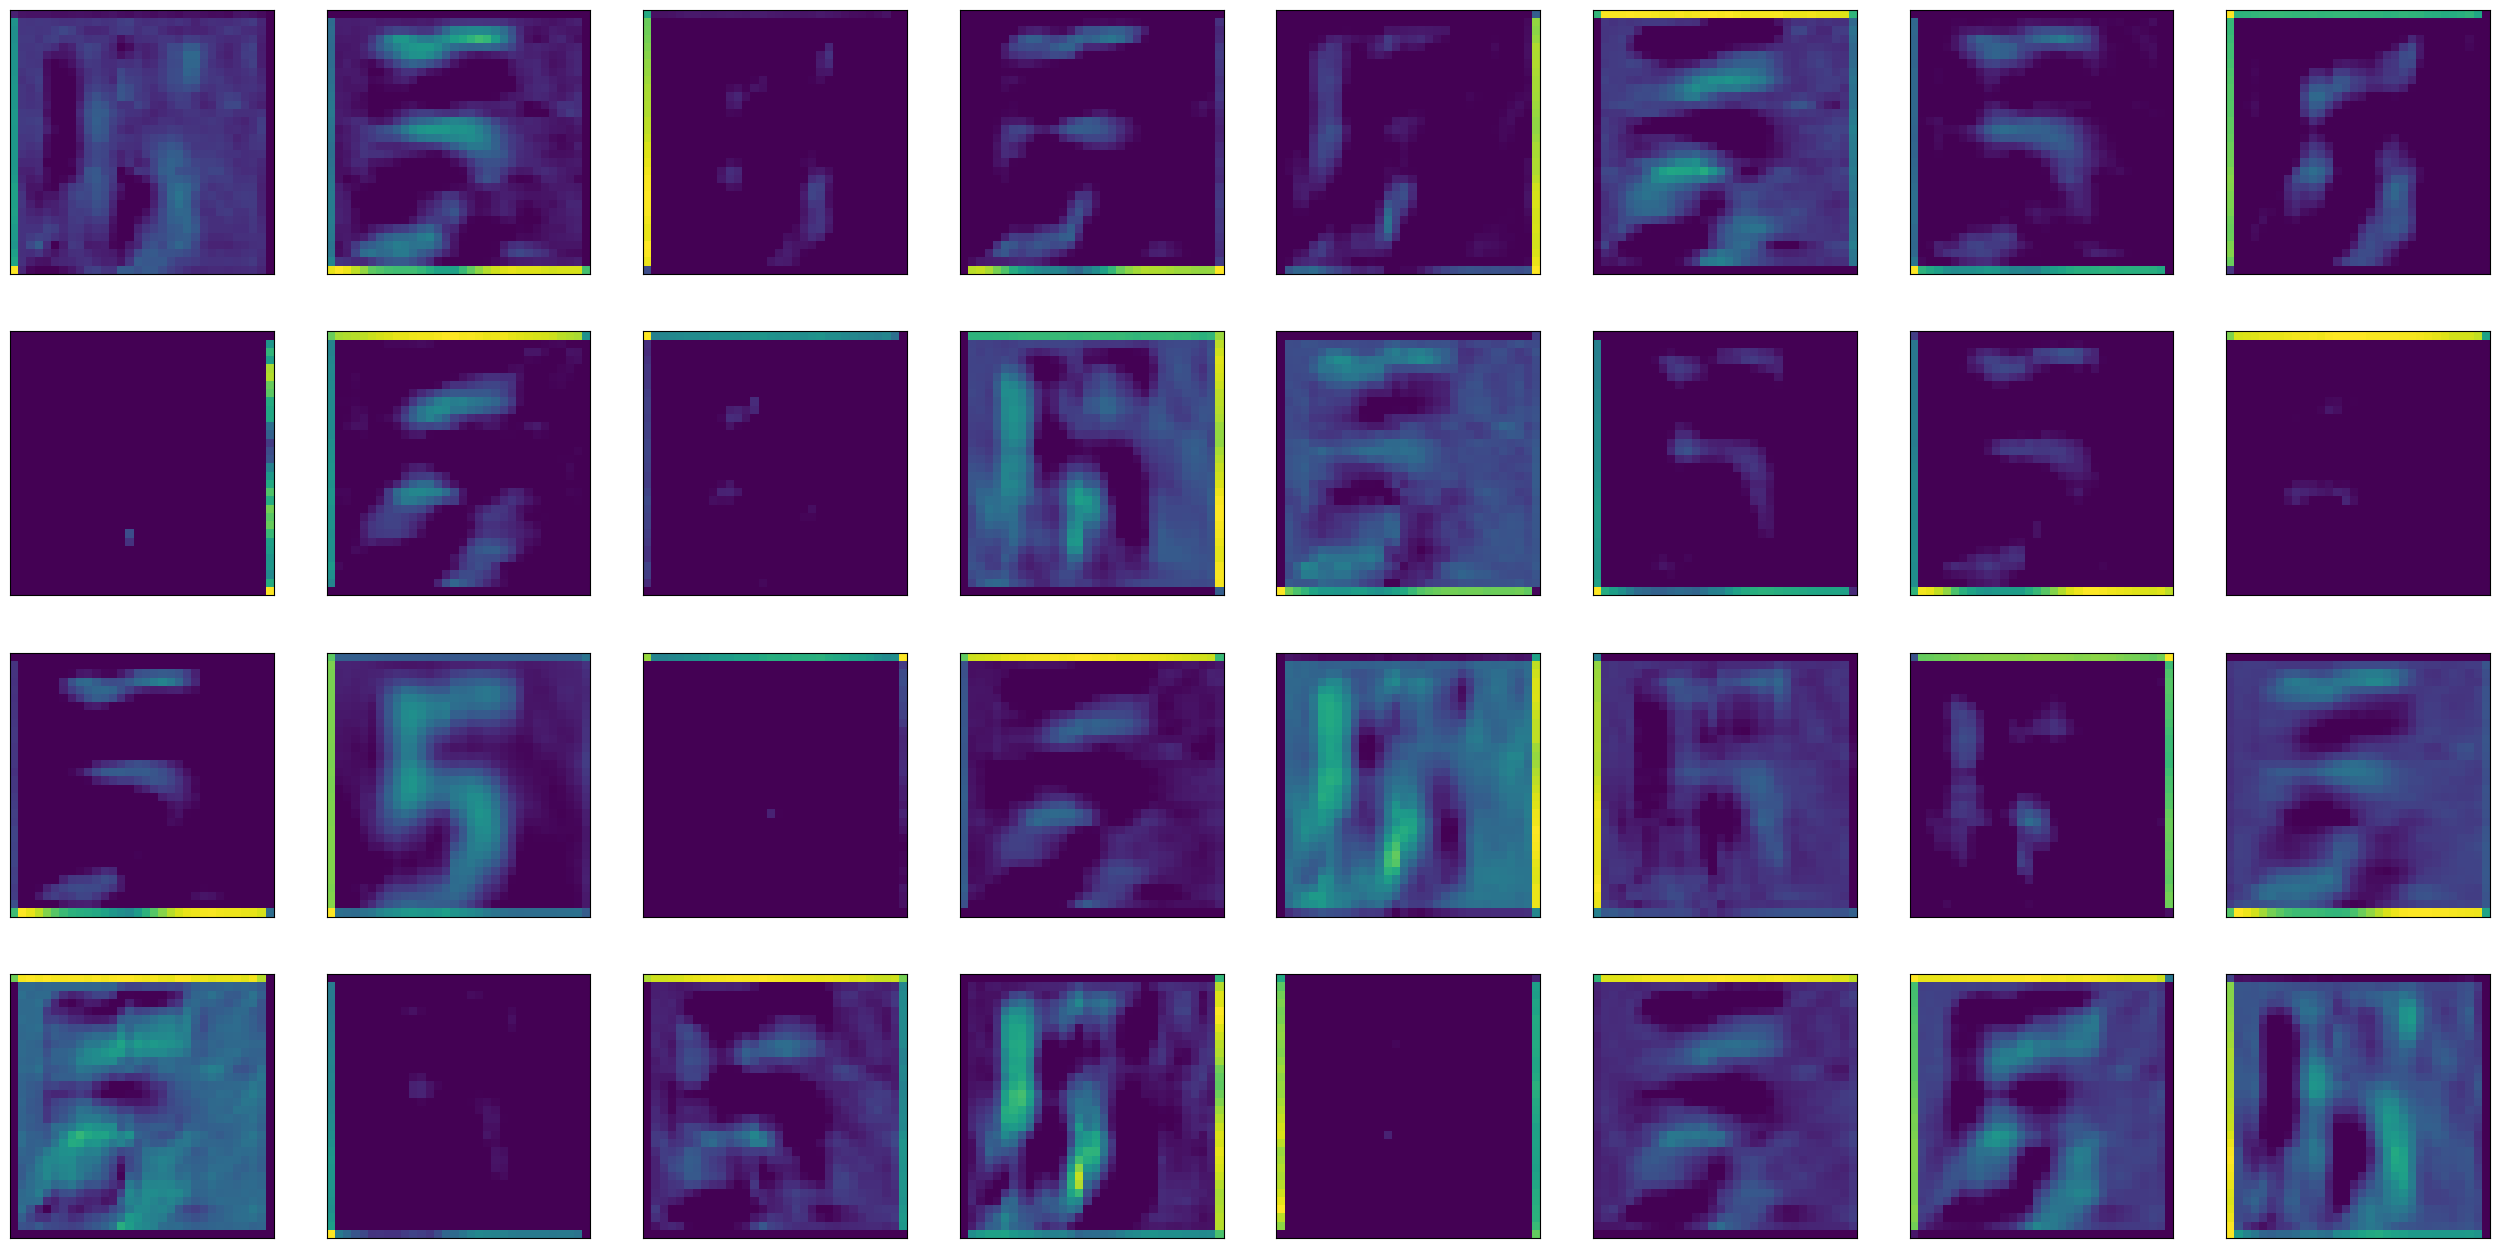

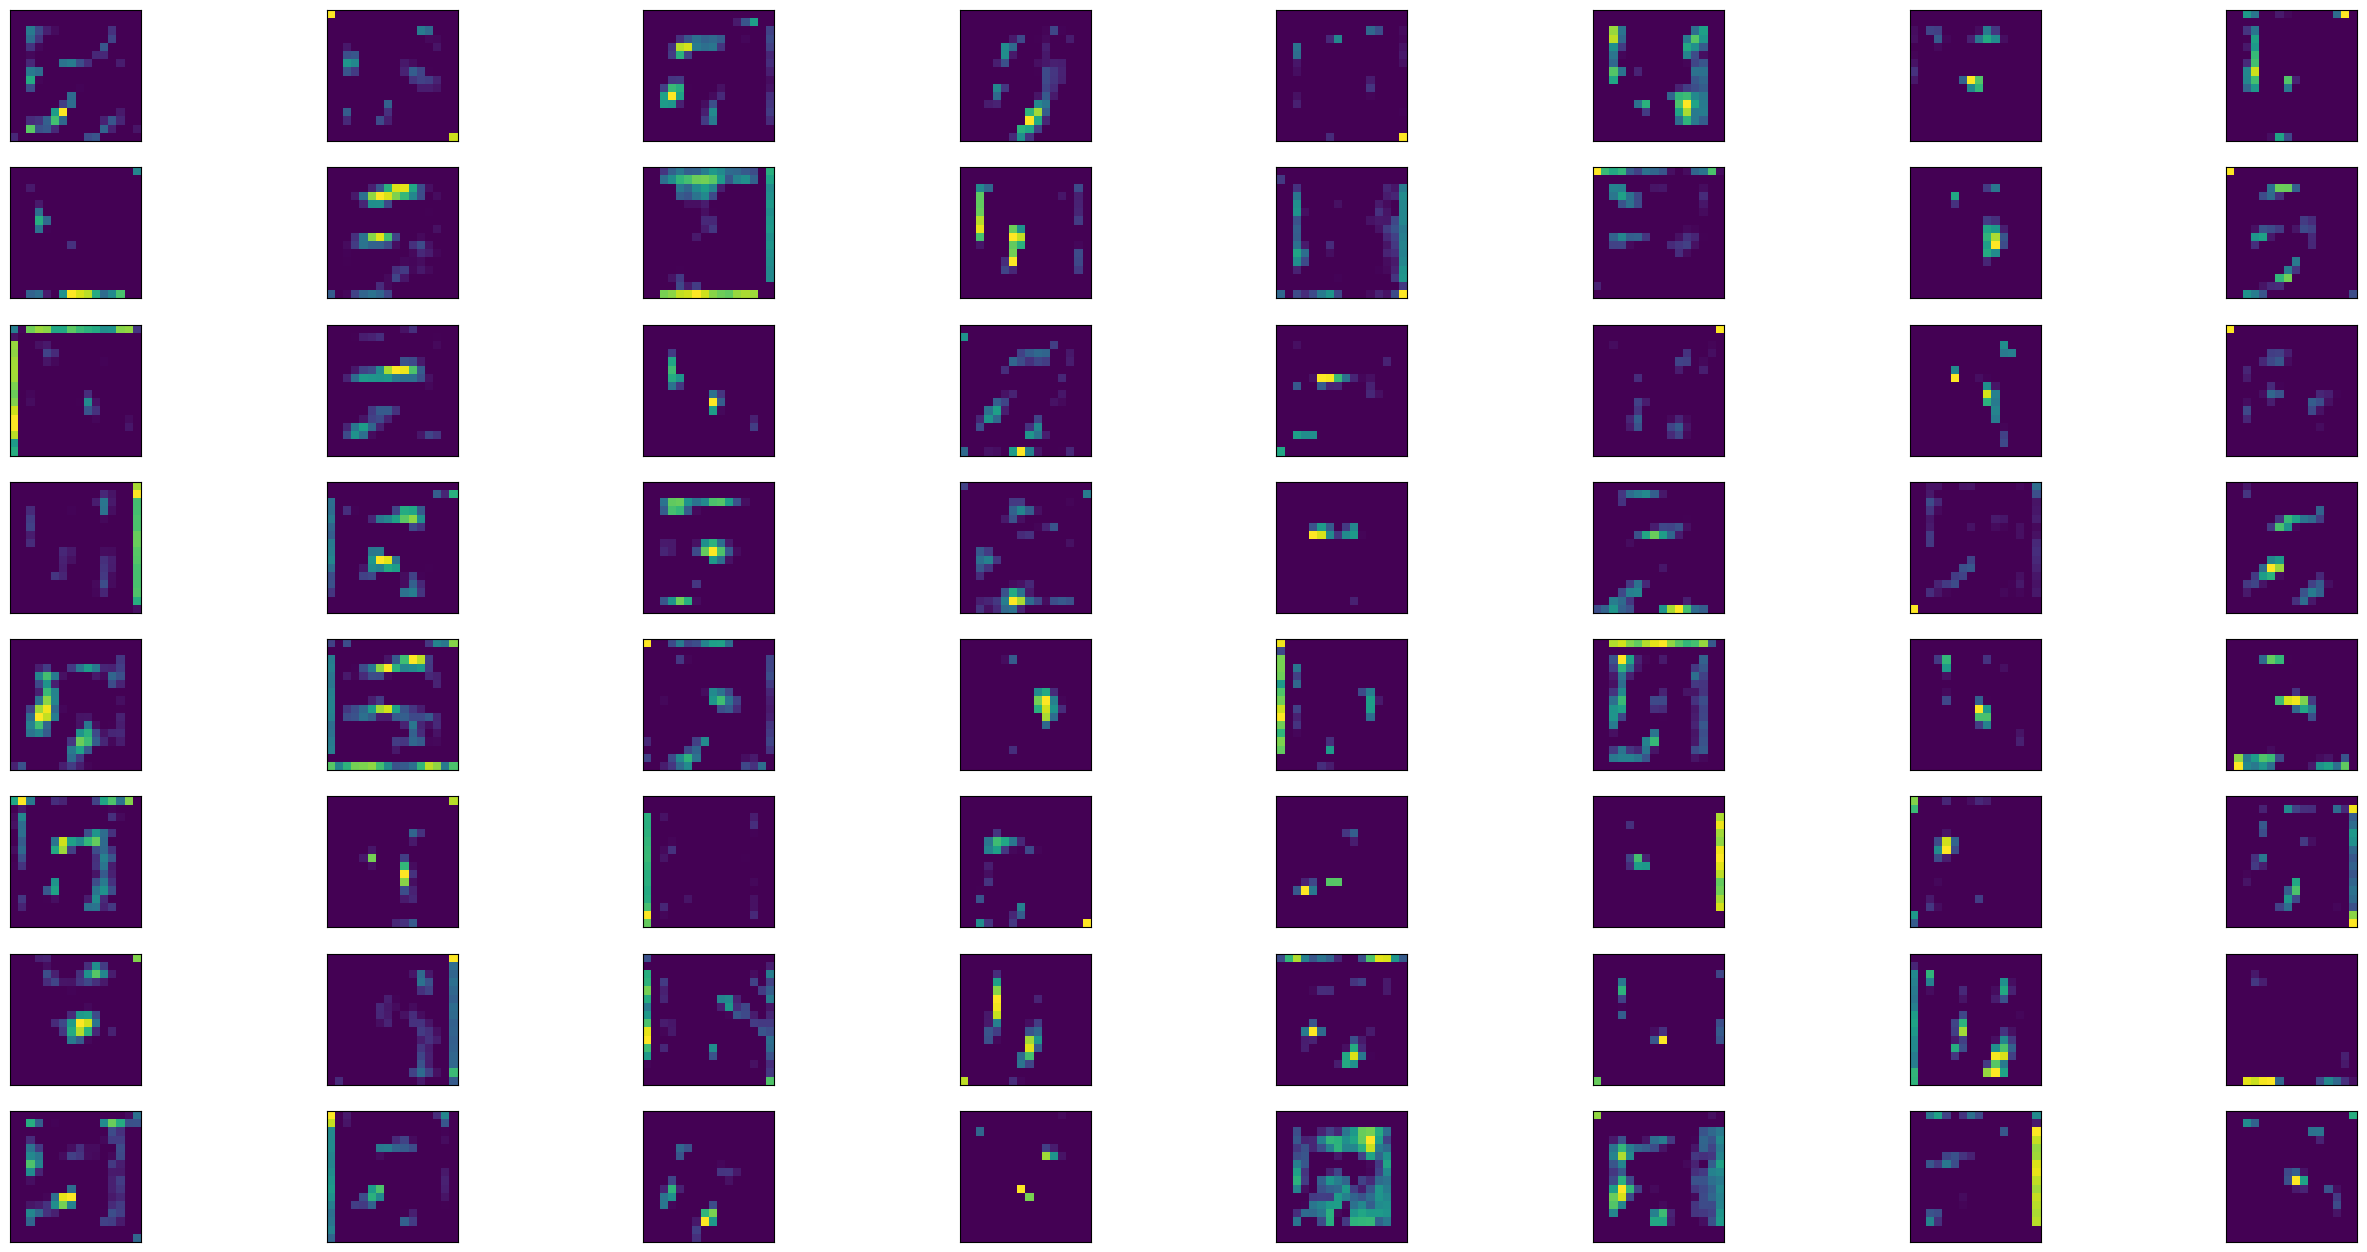

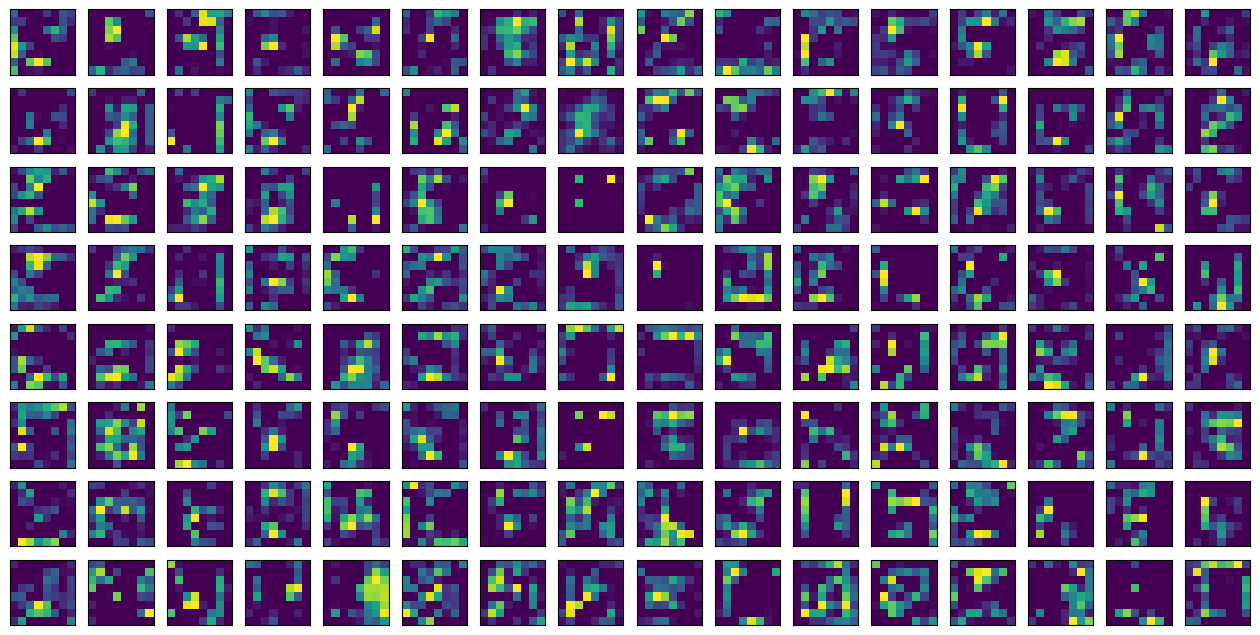

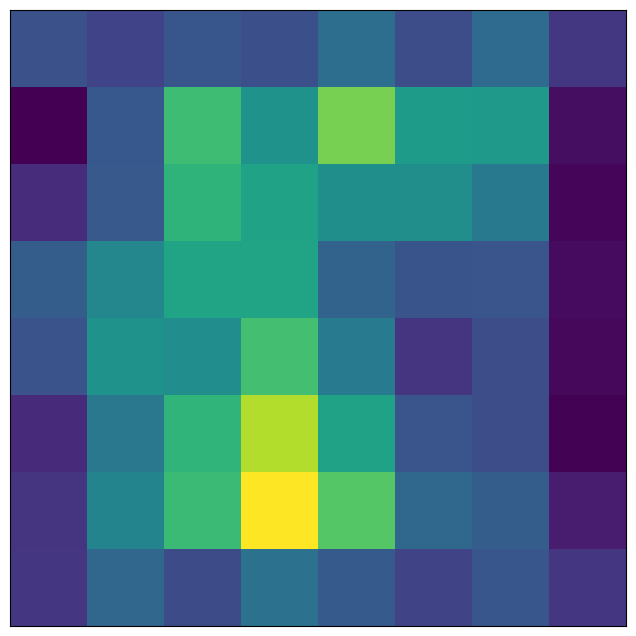

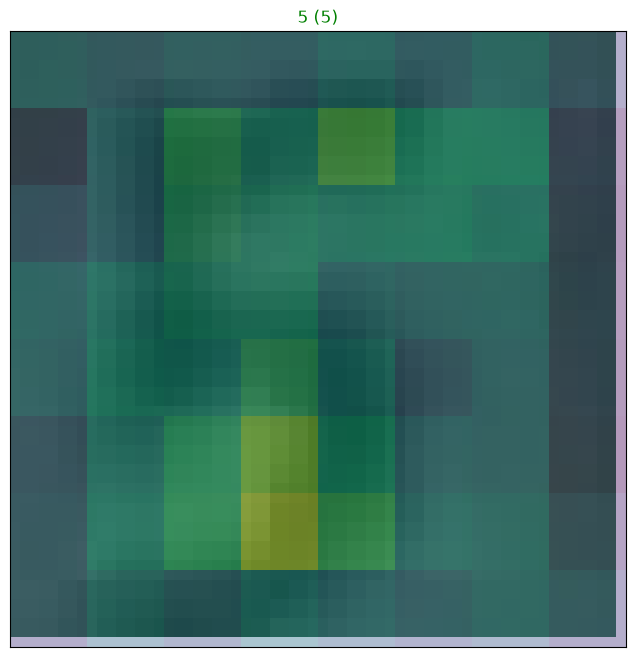

In [32]:
lm.eval()
with torch.no_grad():
    xb, yb = next(iter(tedl))
    xb = xb.to(D)
    yb = yb.to(D)
    yhat = lm(xb)
    pred = yhat.argmax(dim=1)
    # cnn 할 때 사용
    fm1 = lm.c1(xb)
    fm2 = lm.c2(lm.mp(fm1))
    fm3 = lm.c3(lm.mp(fm2))
xb = xb.cpu()
fm1 = fm1.cpu()
fm2 = fm2.cpu()
fm3 = fm3.cpu()
plt.figure(figsize=(8, 8))
plt.xticks([])
plt.yticks([])
plt.imshow(xb[0].permute(1,2,0))
print(fm1.shape)
plt.figure(figsize=(32, 16))
for i in range(fm1.shape[1]):
    plt.subplot(4, 8, i + 1, xticks=[], yticks=[])
    plt.imshow(fm1[0, i])
print(fm2.shape)
plt.figure(figsize=(32, 16))
for i in range(fm2.shape[1]):
    plt.subplot(8, 8, i + 1, xticks=[], yticks=[])
    plt.imshow(fm2[0, i])
print(fm3.shape)
plt.figure(figsize=(16, 8))
for i in range(fm3.shape[1]):
    plt.subplot(8, 16, i + 1, xticks=[], yticks=[])
    plt.imshow(fm3[0, i])
sm = fm3.sum(dim=1)
plt.figure(figsize=(8, 8))
plt.xticks([])
plt.yticks([])
plt.imshow(sm[0])
plt.figure(figsize=(8, 8))
plt.xticks([])
plt.yticks([])
plt.imshow(xb[0].permute(1,2,0))
plt.imshow(sm[0], extent=[0, 32, 32, 0], alpha=0.4, cmap="viridis")
pi = teds.classes[pred[0].item()]
ti = teds.classes[yb[0].item()]
plt.title(f"{pi} ({ti})", color="g" if pi == ti else "r")